# Is this image Italian brainrot?

A small, end-to-end image-classification study: data → baseline → models → validation → error analysis → conclusions.
The notebook runs top to bottom in ~15 minutes on a laptop CPU. Run `python -m src.prepare_data` once before it (see README).

In [4]:
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from PIL import Image
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from tensorflow import keras

from src.config import (CLASS_NAMES, DATA_DIR, FIGURES_DIR, IMG_SIZE, INDEX_CSV, METRICS_PATH,
                        MODEL_PATH, SEED)
from src.model import build_model, extract_embeddings, make_dataset, unfreeze_top

keras.utils.set_random_seed(SEED)          # python, numpy and tensorflow seeds
tf.config.experimental.enable_op_determinism()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 90

print("python", platform.python_version(), "| tensorflow", tf.__version__,
      "| scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

python 3.13.8 | tensorflow 2.21.0 | scikit-learn 1.9.1 | numpy 2.5.4 | pandas 3.1.0


## 1. The question

**What we predict.** Given one image, is it an *Italian brainrot* character (binary: 1 = brainrot, 0 = not)?
"Italian brainrot" is a 2025 TikTok meme genre: AI-generated surreal hybrids of animals and objects
(a shark in sneakers, a ballerina with a cappuccino head) with absurd Italian-sounding names.

**Why it matters.** A feed or a parental-control filter may want to detect (or simply count) this content.
The hard part is that brainrot images are AI-generated, so a naive model can learn
*"AI-generated vs real photo"* instead of *"brainrot vs not brainrot"*. The whole design below
is built to detect and measure that shortcut.

**Data** (prepared by `src/prepare_data.py`):

| class | source | images | origin |
|---|---|---|---|
| 1 brainrot | `brainrot` | 5000 | Kaggle *Largest Italian Brainrot Images Dataset* (Italian Brainrot Wiki) |
| 0 not brainrot | `ai_normal` | 500 | Hugging Face *midjourney-dalle-sd-dataset* (test split, "fake") — ordinary AI images, the **hard negatives** |
| 0 not brainrot | `photo` | 500 + 4000 | same HF dataset ("real") + Imagenette (10 ImageNet classes) |

Every image went through the same steps: RGB → centre square crop → 256×256 → JPEG quality 90,
so size, aspect ratio and compression cannot reveal the class.

## 2. Inspecting the data

In [5]:
df = pd.read_csv(INDEX_CSV)
print(df.shape)
print("missing values:", int(df.isna().sum().sum()))
counts = df.groupby(["source", "split"]).size().unstack()
counts["total"] = counts.sum(axis=1)
counts

(9982, 5)
missing values: 0


split,test,train,val,total
source,,,,
ai_normal,75,350,75,500
brainrot,748,3487,747,4982
photo,675,3150,675,4500


In [6]:
print("class balance:", df["label"].value_counts(normalize=True).round(3).to_dict())
print("share of hard negatives inside class 0:", round((df["source"] == "ai_normal").sum() / (df["label"] == 0).sum(), 3))

class balance: {0: 0.501, 1: 0.499}
share of hard negatives inside class 0: 0.1


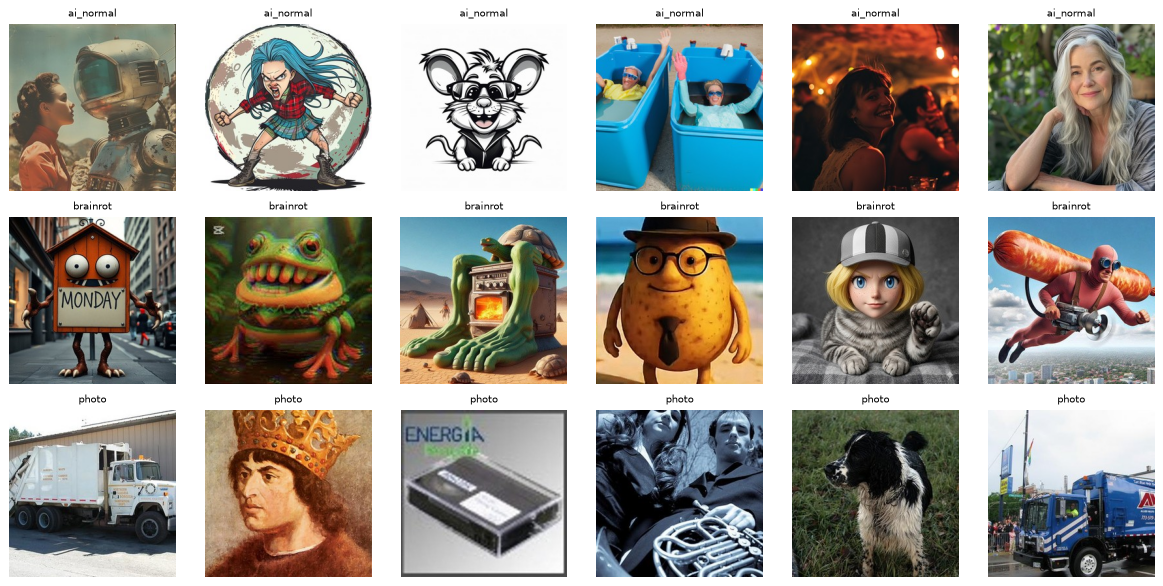

In [7]:
def show_grid(paths, titles=None, ncols=6, size=2.2, path=None):
    if not paths:
        print("(nothing to show)")
        return
    nrows = int(np.ceil(len(paths) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size))
    for ax in np.ravel(axes):
        ax.axis("off")
    for i, (ax, p) in enumerate(zip(np.ravel(axes), paths)):
        ax.imshow(Image.open(p))
        if titles is not None:
            ax.set_title(titles[i], fontsize=8)
    plt.tight_layout()
    if path:
        fig.savefig(FIGURES_DIR / path, bbox_inches="tight")
    plt.show()


sample = df.groupby("source").sample(6, random_state=SEED)
show_grid(sample["path"].tolist(), sample["source"].tolist(), path="examples.png")

Simple pixel statistics per source. If the classes were already separated by brightness or colourfulness,
a model could win without understanding content — that is what the colour-histogram baseline will measure.

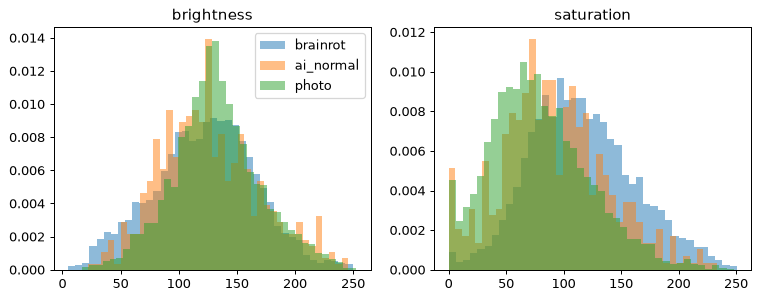

,brightness,saturation
source,,
ai_normal,126.5,91.900002
brainrot,122.5,115.900002
photo,132.5,79.400002


In [8]:
def pixel_stats(path):
    hsv = np.asarray(Image.open(path).convert("HSV").resize((64, 64)), dtype="float32")
    return hsv[..., 2].mean(), hsv[..., 1].mean()  # brightness, saturation


stats = pd.DataFrame([pixel_stats(p) for p in df["path"]], columns=["brightness", "saturation"])
stats["source"] = df["source"].values

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ["brightness", "saturation"]):
    for src in ["brainrot", "ai_normal", "photo"]:
        ax.hist(stats.loc[stats["source"] == src, col], bins=40, alpha=0.5, density=True, label=src)
    ax.set_title(col)
axes[0].legend()
fig.savefig(FIGURES_DIR / "pixel_stats.png", bbox_inches="tight")
plt.show()
stats.groupby("source").mean().round(1)

**Observations.** The two classes are balanced (≈50/50), so accuracy would not be misleading, but we still report
balanced accuracy and PR-AUC. No values are missing; 18 exact/near-exact duplicates (same 64-bit difference hash)
were removed *before* splitting, so no picture can sit in both train and test.
Brainrot images are a little more saturated than photos — a hint that colour alone may already carry signal.

## 3–6. Baselines, preprocessing, models and validation scheme

**Validation scheme.** Images are independent (no users, no time order, duplicates removed),
so a stratified split is valid. We stratify by **source** (which also stratifies the label),
so every fold contains the same share of hard negatives:

* `train` 70 % / `val` 15 % / `test` 15 % — `test` is used **once**, at the very end;
* for the scikit-learn models: 5-fold stratified CV on `train + val` ("dev"), giving mean ± std.

**Models** (from trivial to strong):

| model | why it is here |
|---|---|
| Majority class | the floor any model must beat |
| Colour histogram + logistic regression | a cheap linear model on *global colour only*; if it scores high, the task is partly a colour shortcut |
| MobileNetV2 embeddings + logistic regression | frozen ImageNet features, only a linear layer is learnt — fast, cross-validatable |
| Fine-tuned MobileNetV2 (Keras) | the deployed model: augmentation + training the top 30 layers of the network |

**Preprocessing and leakage.** Image standardisation is a fixed, per-image operation (no statistics learnt from data),
so it cannot leak. Everything that *is* learnt from data — `StandardScaler` — sits inside a
`Pipeline` and is refitted in every CV fold. Augmentation is part of the Keras model and only active during training.

In [9]:
dev = df[df["split"].isin(["train", "val"])].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_folds = list(cv.split(dev, dev["source"]))  # stratify the folds by source
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1", "bal_acc": "balanced_accuracy"}

### Features for the scikit-learn models

In [10]:
def color_histogram(path, bins=8):
    # 8x8x8 joint HSV histogram = 512 numbers that describe only the colour palette
    hsv = np.asarray(Image.open(path).convert("HSV").resize((64, 64))).reshape(-1, 3)
    hist, _ = np.histogramdd(hsv, bins=bins, range=[(0, 256)] * 3)
    return hist.ravel() / hist.sum()


hist_all = np.stack([color_histogram(p) for p in df["path"]])

emb_file = DATA_DIR / "embeddings.npy"   # cache: computing takes ~3 min on CPU
if emb_file.exists():
    emb_all = np.load(emb_file)
else:
    emb_all = extract_embeddings(df["path"])
    np.save(emb_file, emb_all)

row = {p: i for i, p in enumerate(df["path"])}
take = lambda feats, part: feats[[row[p] for p in part["path"]]]
print("colour histogram:", hist_all.shape, "| embeddings:", emb_all.shape)

colour histogram: (9982, 512) | embeddings: (9982, 1280)


### Cross-validation of the baselines and the embeddings model

In [11]:
sk_models = {
    "majority class": (DummyClassifier(strategy="most_frequent"), hist_all),
    "colour hist + logreg": (make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)), hist_all),
    "embeddings + logreg": (make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)), emb_all),
}

cv_rows = []
for name, (model, feats) in sk_models.items():
    res = cross_validate(model, take(feats, dev), dev["label"], cv=cv_folds, scoring=scoring)
    row_ = {"model": name}
    for m in scoring:
        row_[m] = f"{res['test_' + m].mean():.3f} ± {res['test_' + m].std():.3f}"
    cv_rows.append(row_)

cv_table = pd.DataFrame(cv_rows).set_index("model")
cv_table

,roc_auc,pr_auc,f1,bal_acc
model,,,,
majority class,0.500 ± 0.000,0.499 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
colour hist + logreg,0.775 ± 0.011,0.732 ± 0.010,0.723 ± 0.009,0.722 ± 0.009
embeddings + logreg,0.978 ± 0.002,0.976 ± 0.002,0.931 ± 0.003,0.931 ± 0.003


The majority class gets ROC-AUC 0.5 and F1 0 (it never predicts "brainrot") — the floor.
Colour alone is well above chance, which confirms there is a style signal unrelated to *what* is depicted.
The frozen embeddings are far better, with a tiny spread across folds, so the estimate is stable.

### Fine-tuned MobileNetV2 (Keras)

Two stages, the standard transfer-learning recipe:
1. **Head only** — the pretrained network is frozen; only the final dense layer learns (lr 1e-3).
2. **Fine-tuning** — the top 30 layers are unfrozen with a 100× smaller learning rate (1e-5),
   so the pretrained features are adjusted, not destroyed. BatchNorm layers stay frozen (their ImageNet statistics
   would otherwise be overwritten by noisy batch statistics). `EarlyStopping` on validation loss keeps the best epoch.

In [12]:
train = df[df["split"] == "train"]
val = df[df["split"] == "val"]
train_ds = make_dataset(train["path"], train["label"], training=True)
val_ds = make_dataset(val["path"], val["label"])

model = build_model()
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(name="auc"), "accuracy"])
hist_head = model.fit(train_ds, validation_data=val_ds, epochs=5, verbose=2)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5


c:\PythonProjects\ML_Brainrot\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


219/219 - 243s - 1s/step - accuracy: 0.8497 - auc: 0.9223 - loss: 0.3811 - val_accuracy: 0.8637 - val_auc: 0.9627 - val_loss: 0.3225
Epoch 2/5
219/219 - 179s - 816ms/step - accuracy: 0.9183 - auc: 0.9688 - loss: 0.2315 - val_accuracy: 0.8798 - val_auc: 0.9753 - val_loss: 0.2890
Epoch 3/5
219/219 - 235s - 1s/step - accuracy: 0.9284 - auc: 0.9721 - loss: 0.2172 - val_accuracy: 0.9185 - val_auc: 0.9802 - val_loss: 0.1953
Epoch 4/5
219/219 - 200s - 913ms/step - accuracy: 0.9343 - auc: 0.9770 - loss: 0.1921 - val_accuracy: 0.9312 - val_auc: 0.9822 - val_loss: 0.1784
Epoch 5/5
219/219 - 245s - 1s/step - accuracy: 0.9403 - auc: 0.9813 - loss: 0.1746 - val_accuracy: 0.9352 - val_auc: 0.9833 - val_loss: 0.1713


In [13]:
unfreeze_top(model, n_layers=30)
model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(name="auc"), "accuracy"])
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
hist_ft = model.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=[early_stop], verbose=2)

MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
model.save(MODEL_PATH)

Epoch 1/8
219/219 - 288s - 1s/step - accuracy: 0.9438 - auc: 0.9826 - loss: 0.1668 - val_accuracy: 0.9405 - val_auc: 0.9869 - val_loss: 0.1642
Epoch 2/8
219/219 - 204s - 931ms/step - accuracy: 0.9519 - auc: 0.9874 - loss: 0.1397 - val_accuracy: 0.9466 - val_auc: 0.9890 - val_loss: 0.1419
Epoch 3/8
219/219 - 136s - 620ms/step - accuracy: 0.9609 - auc: 0.9915 - loss: 0.1123 - val_accuracy: 0.9512 - val_auc: 0.9903 - val_loss: 0.1254
Epoch 4/8
219/219 - 137s - 625ms/step - accuracy: 0.9672 - auc: 0.9942 - loss: 0.0933 - val_accuracy: 0.9539 - val_auc: 0.9910 - val_loss: 0.1290
Epoch 5/8
219/219 - 164s - 747ms/step - accuracy: 0.9652 - auc: 0.9936 - loss: 0.0972 - val_accuracy: 0.9539 - val_auc: 0.9912 - val_loss: 0.1213
Epoch 6/8
219/219 - 101s - 463ms/step - accuracy: 0.9692 - auc: 0.9946 - loss: 0.0887 - val_accuracy: 0.9539 - val_auc: 0.9917 - val_loss: 0.1268
Epoch 7/8
219/219 - 67s - 307ms/step - accuracy: 0.9757 - auc: 0.9955 - loss: 0.0749 - val_accuracy: 0.9552 - val_auc: 0.9918 -

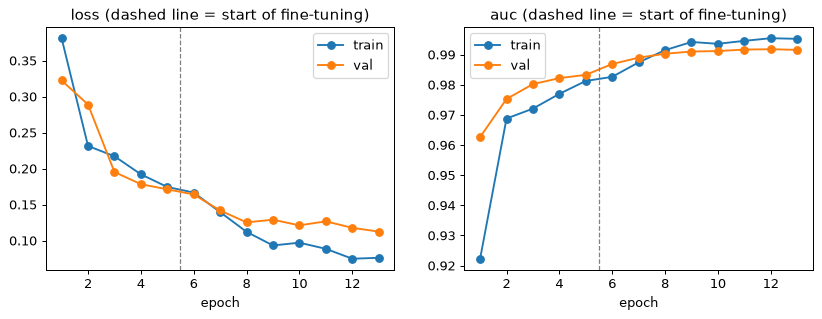

In [14]:
def join_history(*histories):
    out = {}
    for h in histories:
        for k, v in h.history.items():
            out.setdefault(k, []).extend(v)
    return out


h = join_history(hist_head, hist_ft)
epochs = range(1, len(h["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, metric in zip(axes, ["loss", "auc"]):
    ax.plot(epochs, h[metric], "o-", label="train")
    ax.plot(epochs, h["val_" + metric], "o-", label="val")
    ax.axvline(len(hist_head.history["loss"]) + 0.5, color="grey", ls="--", lw=1)
    ax.set_title(metric + " (dashed line = start of fine-tuning)")
    ax.set_xlabel("epoch")
    ax.legend()
fig.savefig(FIGURES_DIR / "learning_curves.png", bbox_inches="tight")
plt.show()

**Decision threshold.** The model outputs a probability. Instead of assuming 0.5, we choose the threshold
that maximises balanced accuracy **on the validation set**, and then keep it fixed for the test set and the app.
The plot below shows the trade-off: lowering the threshold catches more brainrot (recall) at the cost of more
false alarms (specificity), and the histogram shows where each source's probabilities fall relative to the cut.

In [15]:
val_prob = model.predict(make_dataset(val["path"]), verbose=0).ravel()
val_y = val["label"].values
grid = np.linspace(0.05, 0.95, 91)
bal_acc_grid = [balanced_accuracy_score(val_y, val_prob >= t) for t in grid]
threshold = float(grid[np.argmax(bal_acc_grid)])
print(f"chosen threshold: {threshold:.2f}")

chosen threshold: 0.35


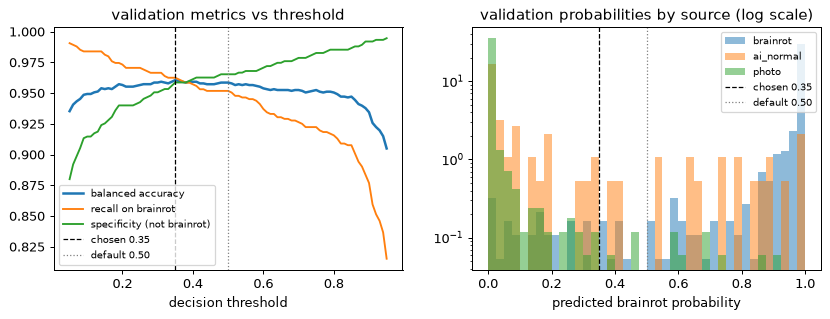

In [16]:
recall_grid = [(val_prob[val_y == 1] >= t).mean() for t in grid]       # brainrot caught
specificity_grid = [(val_prob[val_y == 0] < t).mean() for t in grid]  # non-brainrot left alone

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
ax = axes[0]
ax.plot(grid, bal_acc_grid, lw=2, label="balanced accuracy")
ax.plot(grid, recall_grid, label="recall on brainrot")
ax.plot(grid, specificity_grid, label="specificity (not brainrot)")
ax.set_xlabel("decision threshold")
ax.set_title("validation metrics vs threshold")

ax = axes[1]
bins = np.linspace(0, 1, 41)
for src in ["brainrot", "ai_normal", "photo"]:
    ax.hist(val_prob[val["source"].values == src], bins=bins, alpha=0.5, density=True, label=src)
ax.set_yscale("log")
ax.set_xlabel("predicted brainrot probability")
ax.set_title("validation probabilities by source (log scale)")

for ax in axes:
    ax.axvline(threshold, color="black", ls="--", lw=1, label=f"chosen {threshold:.2f}")
    ax.axvline(0.5, color="grey", ls=":", lw=1, label="default 0.50")
    ax.legend(fontsize=8)
fig.savefig(FIGURES_DIR / "threshold_selection.png", bbox_inches="tight")
plt.show()

## 7–8. Metrics and comparison on the held-out test set

Metrics: **ROC-AUC** (ranking quality, threshold-free), **PR-AUC** (focuses on the brainrot class),
**F1** and **balanced accuracy** at the chosen threshold. Classes are balanced, but class 0 mixes
two very different sources, so the most informative numbers are the **per-source error rates** further below.
The scikit-learn models are refitted on all of `dev`; the Keras model was trained on `train` only.

In [17]:
test_prob = {}
for name, (sk_model, feats) in sk_models.items():
    sk_model.fit(take(feats, dev), dev["label"])
    test_prob[name] = sk_model.predict_proba(take(feats, test))[:, 1]
test_prob["fine-tuned MobileNetV2"] = model.predict(make_dataset(test["path"]), verbose=0).ravel()

y_test = test["label"].values
rows = []
for name, prob in test_prob.items():
    t = threshold if name == "fine-tuned MobileNetV2" else 0.5
    pred = prob >= t
    rows.append({
        "model": name,
        "roc_auc": roc_auc_score(y_test, prob),
        "pr_auc": average_precision_score(y_test, prob),
        "f1": f1_score(y_test, pred),
        "bal_acc": balanced_accuracy_score(y_test, pred),
    })
test_table = pd.DataFrame(rows).set_index("model").round(3)
test_table

,roc_auc,pr_auc,f1,bal_acc
model,,,,
majority class,0.500,0.499,0.000,0.500
colour hist + logreg,0.773,0.718,0.725,0.717
embeddings + logreg,0.972,0.969,0.931,0.931
fine-tuned MobileNetV2,0.986,0.982,0.951,0.951


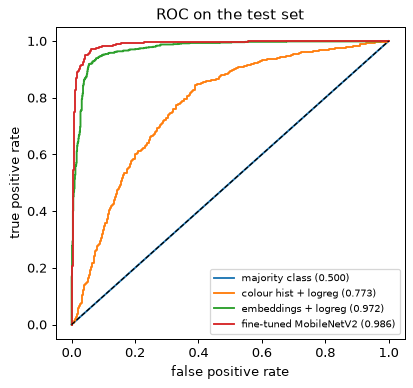

In [18]:
fig, ax = plt.subplots(figsize=(5, 4.5))
for name, prob in test_prob.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, prob):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("ROC on the test set")
ax.legend(fontsize=8)
fig.savefig(FIGURES_DIR / "roc_test.png", bbox_inches="tight")
plt.show()

### Errors per source — the key table

For `brainrot` the error is a miss (false negative); for `ai_normal` and `photo` it is a false alarm (false positive).
If the model had only learnt "AI-generated ⇒ brainrot", the error on `ai_normal` would be close to 100 %.

In [19]:
def error_by_source(prob, t):
    wrong = (prob >= t).astype(int) != y_test
    return pd.Series(wrong).groupby(test["source"].values).mean()


per_source = pd.DataFrame({
    name: error_by_source(prob, threshold if name == "fine-tuned MobileNetV2" else 0.5)
    for name, prob in test_prob.items()
}).T
per_source.columns = [f"error on {c}" for c in per_source.columns]
per_source = per_source.round(3)
print("test images per source:", test["source"].value_counts().to_dict())
per_source

test images per source: {'brainrot': 748, 'photo': 675, 'ai_normal': 75}


,error on ai_normal,error on brainrot,error on photo
majority class,0.000,1.000,0.000
colour hist + logreg,0.533,0.253,0.289
embeddings + logreg,0.387,0.072,0.030
fine-tuned MobileNetV2,0.387,0.045,0.015


### Would more hard negatives help?

Only 10 % of class 0 are ordinary AI images. To see whether that is the bottleneck, we re-run the cheap
embeddings model in the same 5 CV folds, keeping 0 %, 25 %, 50 % or 100 % of the `ai_normal` images in each
training fold (validation folds stay complete).

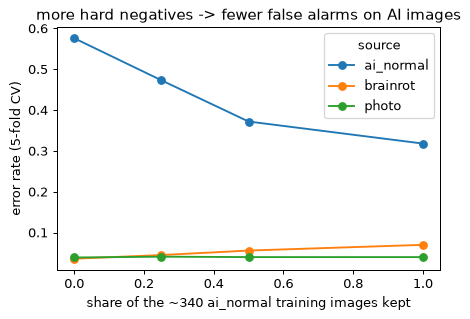

source,ai_normal,brainrot,photo
share of hard negatives kept,,,
0.00,0.576,0.036,0.039
0.25,0.473,0.045,0.041
0.50,0.372,0.056,0.040
1.00,0.318,0.070,0.040


In [20]:
dev_emb, dev_y, dev_src = take(emb_all, dev), dev["label"].values, dev["source"].values
rng = np.random.default_rng(SEED)
curve_rows = []
for share in [0, 0.25, 0.5, 1.0]:
    for fold, (tr, va) in enumerate(cv_folds):
        ai_idx = tr[dev_src[tr] == "ai_normal"]
        kept_ai = rng.choice(ai_idx, int(len(ai_idx) * share), replace=False)
        tr_used = np.concatenate([tr[dev_src[tr] != "ai_normal"], kept_ai])
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
        clf.fit(dev_emb[tr_used], dev_y[tr_used])
        wrong = clf.predict(dev_emb[va]) != dev_y[va]
        for src in ["ai_normal", "brainrot", "photo"]:
            curve_rows.append({"share of hard negatives kept": share, "source": src,
                               "error": wrong[dev_src[va] == src].mean()})

curve = (pd.DataFrame(curve_rows)
         .groupby(["share of hard negatives kept", "source"])["error"].mean().unstack().round(3))
fig, ax = plt.subplots(figsize=(5.5, 3.5))
curve.plot(marker="o", ax=ax)
ax.set_ylabel("error rate (5-fold CV)")
ax.set_xlabel(f"share of the ~{len(ai_idx)} ai_normal training images kept")
ax.set_title("more hard negatives -> fewer false alarms on AI images")
fig.savefig(FIGURES_DIR / "hard_negative_curve.png", bbox_inches="tight")
plt.show()
curve

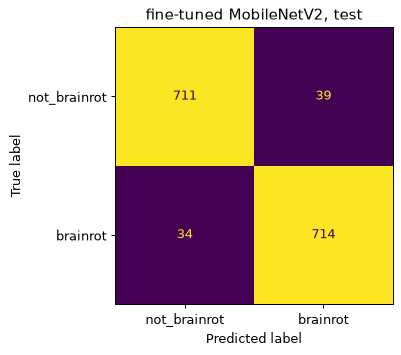

In [21]:
best_prob = test_prob["fine-tuned MobileNetV2"]
best_pred = (best_prob >= threshold).astype(int)
fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, best_pred), display_labels=CLASS_NAMES).plot(ax=ax, colorbar=False)
ax.set_title("fine-tuned MobileNetV2, test")
fig.savefig(FIGURES_DIR / "confusion_matrix.png", bbox_inches="tight")
plt.show()

## 9. Error analysis

### What do the most confident mistakes look like?

false positives: 39, false negatives: 34
False positives (not brainrot, predicted brainrot):


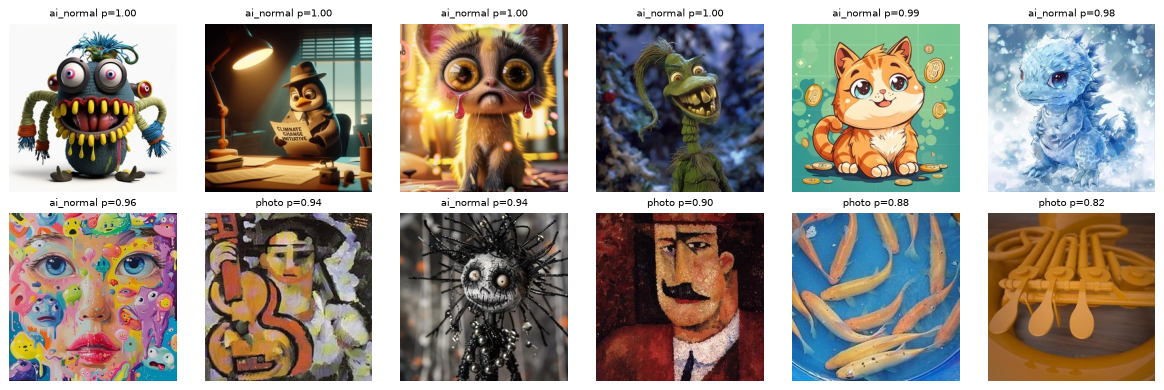

In [22]:
test_view = test.assign(prob=best_prob, pred=best_pred)
fp = test_view[(test_view["pred"] == 1) & (test_view["label"] == 0)].sort_values("prob", ascending=False).head(12)
fn = test_view[(test_view["pred"] == 0) & (test_view["label"] == 1)].sort_values("prob").head(12)
print(f"false positives: {(test_view['pred'] > test_view['label']).sum()}, "
      f"false negatives: {(test_view['pred'] < test_view['label']).sum()}")
print("False positives (not brainrot, predicted brainrot):")
show_grid(fp["path"].tolist(), [f"{s} p={p:.2f}" for s, p in zip(fp["source"], fp["prob"])], path="false_positives.png")

False negatives (brainrot, predicted not brainrot):


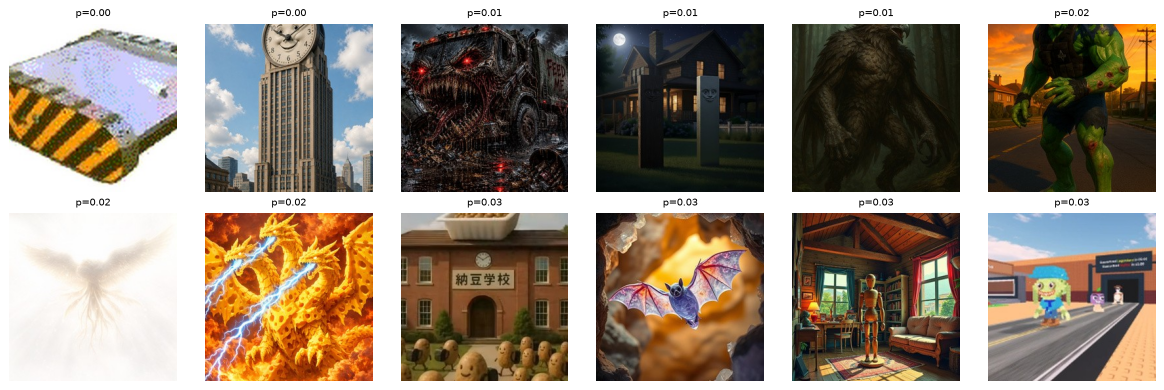

In [23]:
print("False negatives (brainrot, predicted not brainrot):")
show_grid(fn["path"].tolist(), [f"p={p:.2f}" for p in fn["prob"]], path="false_negatives.png")

### Does the model look at the character or at the edges?

Many brainrot images are TikTok frames with a watermark, captions or the character's name near the border.
Two checks:

1. **Border removal.** Keep only the central 60 % of every test image (resized back to 224) and re-score.
   If recall on brainrot collapsed, the model would be reading borders and watermarks.
2. **Occlusion maps.** Slide a grey 32×32 patch over the image and record how much the brainrot probability drops.
   Red = the region the decision depends on. (For very confident images, p ≈ 1.00, hiding a single patch barely
   changes the output, so their maps are flat — the evidence is spread over the whole image.)

In [24]:
def load_center(path, keep=0.6):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.central_crop(img, keep)
    return tf.image.resize(img, (IMG_SIZE, IMG_SIZE))


center_ds = tf.data.Dataset.from_tensor_slices(list(test["path"])).map(load_center).batch(32)
center_prob = model.predict(center_ds, verbose=0).ravel()

border_check = pd.DataFrame({
    "error, full image": error_by_source(best_prob, threshold),
    "error, centre 60% only": error_by_source(center_prob, threshold),
}).round(3)
border_check

,"error, full image","error, centre 60% only"
ai_normal,0.387,0.320
brainrot,0.045,0.091
photo,0.015,0.034


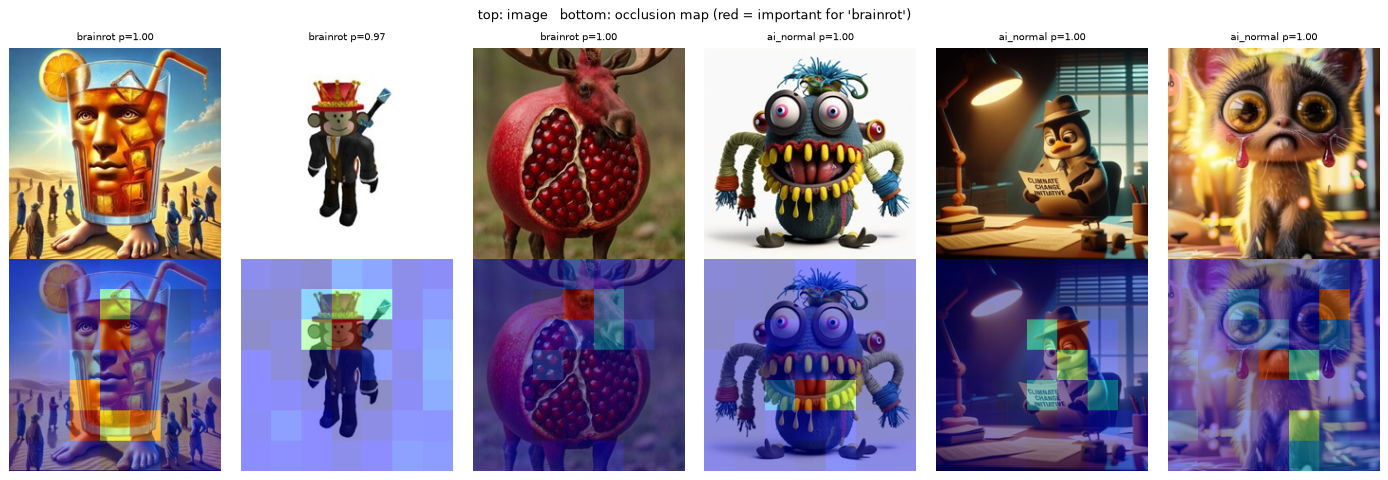

In [25]:
def occlusion_map(img, patch=32):
    # img: (224, 224, 3) array; returns a 7x7 map of probability drops
    base = model.predict(img[None], verbose=0)[0, 0]
    n = IMG_SIZE // patch
    batch = np.repeat(img[None], n * n, axis=0)
    for k in range(n * n):
        r, c = divmod(k, n)
        batch[k, r * patch:(r + 1) * patch, c * patch:(c + 1) * patch] = 127.5
    probs = model.predict(batch, verbose=0).ravel()
    return base, (base - probs).reshape(n, n)


examples = pd.concat([
    test_view[(test_view["label"] == 1) & (test_view["pred"] == 1)].sample(3, random_state=SEED),
    fp.head(3),
])
fig, axes = plt.subplots(2, len(examples), figsize=(2.6 * len(examples), 5.4))
for j, (_, r) in enumerate(examples.iterrows()):
    img = np.asarray(Image.open(r["path"]).resize((IMG_SIZE, IMG_SIZE)), dtype="float32")
    base, heat = occlusion_map(img)
    axes[0, j].imshow(img.astype("uint8"))
    axes[0, j].set_title(f"{r['source']} p={base:.2f}", fontsize=8)
    axes[1, j].imshow(img.astype("uint8"))
    axes[1, j].imshow(np.kron(heat, np.ones((32, 32))), cmap="jet", alpha=0.45)
    for ax in axes[:, j]:
        ax.axis("off")
plt.suptitle("top: image   bottom: occlusion map (red = important for 'brainrot')", fontsize=10)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "occlusion_maps.png", bbox_inches="tight")
plt.show()

## 10. Limitations and conclusions

**What the results support**

* The fine-tuned MobileNetV2 separates brainrot from ordinary **photos** very well: test ROC-AUC 0.986,
  balanced accuracy 0.951, and only 1.5 % of photos are flagged as brainrot.
* Every step of the ladder matters. The majority class gives 0.50, colour alone 0.77, frozen ImageNet features 0.97,
  fine-tuning 0.986. The gain from fine-tuning is small; most of the work is done by the pretrained features.
* Colour alone reaching ROC-AUC 0.77 shows that brainrot has a recognisable *style* (it is the most saturated source),
  independent of what is depicted.
* There is no evidence that the model reads TikTok watermarks or captions. Cropping to the centre 60 % roughly doubles
  the error on brainrot (4.7 % → 9.1 %) **and** on photos (1.5 % → 3.4 %), which is what losing image content does to
  any class.

**What the results do *not* support**

* That the model detects "brainrot" as a concept. **38.7 % of ordinary AI-generated images (29 of 75) are
  called brainrot.** The frozen-feature model fails on exactly the same share. The model has partly learnt
  *"AI-generated character / illustration ⇒ brainrot"*. The confident false positives are cartoon-like
  creatures with big eyes, which shows the class boundary is fuzzy even for a human.
* The hard-negative curve shows the cause and the remedy. With no ordinary AI images in training, 58 % of them are
  misclassified; with all ~340, 32 %, and the curve has not flattened. More hard negatives is the most promising
  next step, at the price of slightly lower brainrot recall (miss rate 3.6 % → 7.0 %).

**Limitations**

* Only 75 hard negatives in the test set, so their error rate is uncertain.
* One meme wave (2025 Italian brainrot, images from one wiki). New meme formats are out of distribution.
* "Brainrot" has no formal definition. Labels come from the source dataset, not from several annotators, and a few
  "ordinary" AI images (fantasy creatures) are arguably brainrot-like.
* Imagenette covers only 10 ImageNet classes, so the photo class is narrow.
* The Keras model was trained once (seed 42). Its seed-to-seed variance was not measured, unlike the 5-fold CV of
  the scikit-learn models.
* Occlusion maps are qualitative and saturate for very confident predictions.

**Bottom line.** As a filter "brainrot vs everyday photos" the model is reliable. As a filter "brainrot vs any
AI-generated picture" it is not yet: roughly one in three ordinary AI images would be flagged.

In [26]:
metrics = {
    "threshold": threshold,
    "test": test_table.to_dict(orient="index"),
    "test_error_by_source": per_source.to_dict(orient="index"),
    "border_check": border_check.to_dict(),
    "cv_dev_5fold": cv_table.to_dict(orient="index"),
    "hard_negative_curve": {str(k): v for k, v in curve.to_dict(orient="index").items()},
    "n_images": {"train": len(train), "val": len(val), "test": len(test)},
}
METRICS_PATH.write_text(json.dumps(metrics, indent=2))
print("saved", METRICS_PATH)

saved C:\PythonProjects\ML_Brainrot\reports\metrics.json


## 11. Reproducibility

* Seed 42 everywhere (`keras.utils.set_random_seed`, `random_state=SEED`), deterministic TensorFlow ops.
* Data: three public sources downloaded by `python -m src.prepare_data` (Kaggle needs a free account token).
* Library versions are printed in the first cell and pinned in `requirements.txt`.
* Run: `jupyter nbconvert --to notebook --execute notebook.ipynb --inplace` (≈15 min on a laptop CPU).